In [4]:
import jax_sn as jsn
%load_ext autoreload
%autoreload 2
import jax_sbgeom

import jax.numpy as jnp
import numpy as onp
from typing import Tuple
import jax
import numpy as onp
from functools import partial
jax.config.update("jax_enable_x64", True)

import pyvista as pv

def remove_zeros(array):
    a = onp.array(array)
    a[onp.abs(a) < 1e-14] = 0.0
    return a

from jax_sn.domain.geometric_domain import GeometricDomain, TopologicalSortedAngle
from jax_sn.solution_domain.solution_domain import FEMMatrices, PrecomputedGeometricData
from jax_sn.domain.geometric_domain import CrossSectionData, CrossSectionDataSingleGroup
from jax_sn.source import Source
from jax_sn.operators.transport_operator import TransportOperatorBatched, TransportOperatorMultipleAnglesVmap, TransportOperatorVmap, TransportOperatorBatchedPallas
from jax_sn.operators.mass_operator import MassOperator
from jax_sn.operators.moment_operator import MomentOperator
from jax_sn.operators.single_group_operator import SingleGroupOperator
from jax_sn.operators.scatter_operator.inscatter_operator import InScatterOperator
from jax_sn.operators.multi_group_operator import MultiGroupOperator
import equinox as eqx
from typing import List
from jax_sn.tools.mesh_tools import _pad_last_dimension
import matplotlib.pyplot as plt
from dataclasses import dataclass
onp.set_printoptions(linewidth = 200)
from finite_elements.test_moment_scatter_operator import _setup_all_sb

In [5]:
from jax_sn.domain.domain_generation import create_cartesian_setup
from jax_sn.solution_domain import BasixLagrangianSimplex
from jax_sn.solution_domain import SolutionDomain
from jax_sn.domain import CrossSectionData, Domain
from jax_sn.source import Source

In [42]:
from finite_elements.test_breeding_blanket import bb_data_dict, base_region_sizes, base_resolutions,  _get_bb_args, _setup_bb_args, _get_bb_args


MGOP, source_eg0, solution_domain = _setup_bb_args(3,2, base_region_sizes(), base_resolutions(), 5.0, 20, 3)


In [43]:
transport_operator = TransportOperatorMultipleAnglesVmap(TransportOperatorBatchedPallas(MGOP.transport_operator.solution_domain_data, MGOP.transport_operator.topological_sorted_angle, 0, 10))

MGOP_new = eqx.tree_at(lambda t : t.transport_operator, MGOP, transport_operator)


In [44]:
from jax_sn.tools.memory_analysis import OperatorAnalysis, TotalOperatorSigmaParametrised

In [45]:
transport_operator = TransportOperatorMultipleAnglesVmap(TransportOperatorBatched(MGOP.transport_operator.solution_domain_data, MGOP.transport_operator.topological_sorted_angle, 0, 100))
OperatorAnalysis.analyze_memory(transport_operator, "inv")

{'peak': 777.5050430297852,
 'argument': 419.6612243652344,
 'output': 329.5898666381836,
 'temp': 28.25647735595703}

In [46]:
{'peak': 1296.9386291503906,
 'argument': 419.6612243652344,
 'output': 329.5898666381836,
 'temp': 547.689826965332}

{'peak': 1296.9386291503906,
 'argument': 419.6612243652344,
 'output': 329.5898666381836,
 'temp': 547.689826965332}

In [47]:
top_single = TransportOperatorBatchedPallas(transport_operator.solution_domain_data, transport_operator.topological_sorted_angle[0], 0, 1)

In [48]:
from jax_sn.operators.transport_operator.transport_operator_imp import transport_inverse_sweep_batched
from jax_sn.operators.transport_operator.transport_operator_pallas import transport_inverse_sweep_batched_pallas
from jax_sn.tools.memory_analysis import _filter_jit_f_to_memory, pytree_nbytes

xs_data =  top_single.solution_domain_data.domain.cross_sections_indexed.map_to_full_array(0)

@eqx.filter_jit
def top(solution_domain_data, xs_data, angles, in_structure, batch_size):
    return transport_inverse_sweep_batched(*solution_domain_data, xs_data, angles, in_structure, batch_size)

@eqx.filter_jit
def top_s(solution_domain_data, xs_based, angles, in_structure, batch_size):
    xs_dataf = xs_based.map_to_full_array(0)
    return transport_inverse_sweep_batched(*solution_domain_data, xs_dataf, angles, in_structure, batch_size)

@eqx.filter_jit
def top_s2(solution_domain_data, xs_based, angles, in_structure, batch_size):
    xs_dataf = xs_based.map_to_full_array(0)
    return transport_inverse_sweep_batched_pallas(*solution_domain_data, xs_dataf, angles, in_structure, batch_size)

print(_filter_jit_f_to_memory(top, top_single.solution_domain_data, xs_data, top_single.topological_sorted_angle, jnp.ones_like(top_single.in_structure()), 1))
print(_filter_jit_f_to_memory(top_s, top_single.solution_domain_data,  top_single.solution_domain_data.domain.cross_sections_indexed, top_single.topological_sorted_angle, jnp.ones_like(top_single.in_structure()), 1))
print(_filter_jit_f_to_memory(top_s2, top_single.solution_domain_data,  top_single.solution_domain_data.domain.cross_sections_indexed, top_single.topological_sorted_angle, jnp.ones_like(top_single.in_structure()), 1))

print(OperatorAnalysis.analyze_memory(top_single, "inv"))


{'peak': 36.97836685180664, 'argument': 32.39153289794922, 'output': 4.577659606933594, 'temp': 0.01258087158203125}
{'peak': 34.69565200805664, 'argument': 29.65105438232422, 'output': 4.577659606933594, 'temp': 0.47034454345703125}
{'peak': 41.566680908203125, 'argument': 29.65105438232422, 'output': 4.577659606933594, 'temp': 7.339973449707031}
{'peak': 41.560577392578125, 'argument': 29.64495086669922, 'output': 4.577659606933594, 'temp': 7.339973449707031}


In [53]:
from jax_sn.operators.transport_operator.transport_operator_pallas import _pad_etoe_pow2, _setup_elements_idx_in_precomp_with_omega_n_calculation_padded, sweep_pl_update, _next_power_of_two
@partial(jax.jit, static_argnums=(6,))
def transport_inverse_sweep_batched_pallas2(geometric_domain    : GeometricDomain, 
                                    fem_matrices               : FEMMatrices, 
                                    precomputed_geometric_data : PrecomputedGeometricData,                                      
                                    cross_sections             : CrossSectionDataSingleGroup, 
                                    topological_sorted_angle   : TopologicalSortedAngle,                                     
                                    x                          : jnp.ndarray,
                                    batch_size                 : int):   

    n_batches                  = jnp.ceil(geometric_domain.n_elements / batch_size).astype(int)        
    
    etoe_pad                   = _pad_etoe_pow2(geometric_domain.etoe)
    print(pytree_nbytes(etoe_pad)/1024**2, "etoe_pad")
    
    def single_batch(batch_i, sweep_result):
        batch_indices                               = jnp.clip(jnp.arange(batch_size) + batch_i * batch_size, 0, geometric_domain.n_elements - 1)    
        batch_elements                              = topological_sorted_angle.levels_argsort[batch_indices]        
        gij_inv_pad, dij_f_p_fm_pad, abs_omega_dot_n_Je, x_i_pad = _setup_elements_idx_in_precomp_with_omega_n_calculation_padded(
                                                                        batch_elements,
                                                                        geometric_domain, 
                                                                        fem_matrices,
                                                                        precomputed_geometric_data,                                      
                                                                        cross_sections, 
                                                                        topological_sorted_angle.angle,
                                                                        x
                                                                        )        
        return sweep_pl_update(batch_elements, gij_inv_pad, x_i_pad, dij_f_p_fm_pad, etoe_pad, abs_omega_dot_n_Je, sweep_result)    

    buffer_sweep = jnp.zeros((geometric_domain.n_elements, _next_power_of_two(fem_matrices.n_basis)), dtype=x.dtype)
    return jax.lax.fori_loop(0, n_batches, single_batch, buffer_sweep)#[:, :fem_matrices.n_basis]
@eqx.filter_jit
def top_s3(solution_domain_data, xs_based, angles, in_structure, batch_size):
    xs_dataf = xs_based.map_to_full_array(0)
    return transport_inverse_sweep_batched_pallas2(*solution_domain_data, xs_dataf, angles, in_structure, batch_size)

print(_filter_jit_f_to_memory(top_s3, top_single.solution_domain_data,  top_single.solution_domain_data.domain.cross_sections_indexed, top_single.topological_sorted_angle, jnp.ones_like(top_single.in_structure()), 1))

1.8310546875 etoe_pad
{'peak': 37.446807861328125, 'argument': 29.65105438232422, 'output': 7.324241638183594, 'temp': 0.47351837158203125}


In [ ]:
from jax_sn.operators.transport_operator.transport_operator_pallas import _next_power_of_two
@eqx.filter_jit
def REEEE(x):
    sweep_b = jnp.ones((x.shape[0],_next_power_of_two(x.shape[-1])))
    sweep_b[:,:] += x[0,0] * x[-1,-1]
    
    return sweep_b[:, :x.shape[-1]] 

x = jnp.ones((100000, 5)) + 1e-5

print(_filter_jit_f_to_memory(REEEE, x))
REEEE(x)

{'peak': 7.629425048828125, 'argument': 3.814697265625, 'output': 3.8147201538085938, 'temp': 1.52587890625e-05}


Array([[2.00002, 2.00002, 2.00002, 2.00002, 2.00002],
       [2.00002, 2.00002, 2.00002, 2.00002, 2.00002],
       [2.00002, 2.00002, 2.00002, 2.00002, 2.00002],
       ...,
       [2.00002, 2.00002, 2.00002, 2.00002, 2.00002],
       [2.00002, 2.00002, 2.00002, 2.00002, 2.00002],
       [2.00002, 2.00002, 2.00002, 2.00002, 2.00002]], dtype=float64)

In [ ]:
4.58094 - 0.

np.float64(3.204345703125)

In [77]:
pytree_nbytes(transport_operator.transport_operator._inv_args(transport_operator.in_structure())[-4]) / 1024**2

np.float64(3.204345703125)

In [52]:
top_single.in_structure()

ShapeDtypeStruct(shape=(60000, 10), dtype=float64)

In [53]:
OperatorAnalysis.analyze_memory(top_single, "inv")

{'peak': 38.80027389526367,
 'argument': 29.64495086669922,
 'output': 4.577659606933594,
 'temp': 4.580940246582031}

In [43]:
OperatorAnalysis.analyze_memory(MGOP_new, "mv")

{'peak': 2274.4807138442993,
 'argument': 750.2127685546875,
 'output': 659.1797103881836,
 'temp': 865.0932006835938}

In [ ]:
rhs_eg0 = MGOP.moment_operator.mv(MGOP.transport_operator.to_energy_group(0).inv(MGOP.mass_operator.mv(source_eg0)))

rhs_total = jnp.stack([rhs_eg0] + [jnp.zeros_like(rhs_eg0) for _ in range(MGOP.n_energy_groups -1)], axis =0)

In [ ]:
import lineax as lx
import equinox as eqx
bicgstab_solver = lx.BiCGStab(1e-20, 1e-20, max_steps = 300)



In [102]:
from jax_sn.operators.multi_group_operator.multi_group_operator_imp import solve_lower_triangular, solve_total

In [115]:
values_lower_triangular = solve_lower_triangular(MGOP, bicgstab_solver, rhs_total)
values_total = solve_total(MGOP, bicgstab_solver, rhs_total)

In [ ]:
MGOP.transport_operator.solution_domain_data.precomputed_geometric_data.vol_jacobians_

(150, 2, 2)

In [121]:
from finite_elements.test_breeding_blanket import _bb_sb, _interp_x, _get_bb_args

def _get_expected_values_sb_bb(dim, degree):
    import StellBlanket as SB
    dim, degree, d_elem_regions, n_elem_regions, d_other_dim, n_other_dim, tn_order = _get_bb_args(dim, degree)
        
    nte, source = _bb_sb(dim,degree, d_elem_regions, n_elem_regions, d_other_dim, n_other_dim, tn_order)
    
    solution_options = SB.Generic_Elements.Solution_Options(tolerance=1e-20, maximum_iterations=200)

    n_groups = nte.energy_set.Boundaries().shape[0] -1
    SB.Generic_Elements.Run_Forward(nte, source, solution_options)
        


    x = onp.array(_interp_x())
    y = onp.zeros_like(x)
    z = onp.zeros_like(x)

    xyz = onp.stack([x, y, z], axis = -1)
    phisb = [SB.Generic_Elements.Interpolate_Moments(xyz, nte.global_moment_solution, nte.energy_set[i], 0, 0) * onp.sqrt(4 * onp.pi) for i in range(n_groups)]
    return phisb


In [ ]:


def test_bb(_setup_bb, expected_value_function = _get_expected_values_sb_bb):
    import lineax as lx
    MGOP, source_eg0, solution_domain, bb_args = _setup_bb

    rhs_eg0 = MGOP.moment_operator.mv(MGOP.transport_operator.to_energy_group(0).inv(MGOP.mass_operator.mv(source_eg0)))
    rhs_total = jnp.stack([rhs_eg0] + [jnp.zeros_like(rhs_eg0) for _ in range(MGOP.n_energy_groups -1)], axis =0)
    bicgstab_solver = lx.BiCGStab(1e-20, 1e-20, max_steps = 300)

    from jax_sn.operators.multi_group_operator.multi_group_operator_imp import solve_lower_triangular, solve_total

    values_lower_triangular = solve_lower_triangular(MGOP, bicgstab_solver, rhs_total)
    values_total            = solve_total(MGOP, bicgstab_solver, rhs_total)

    x = _interp_x()    
    
    dim = bb_args[0]
    d_other = bb_args[-3]
    xyz = jnp.stack([x] + [jnp.full_like(x, d_other / 2)] * (dim-1), axis = -1)

    phi_jsn = [solution_domain.interpolate(xyz, values_lower_triangular[i,0]) for i in range(values_lower_triangular.shape[0])]
    phi_total = [solution_domain.interpolate(xyz, values_total[i,0]) for i in range(values_total.shape[0])]

    dim = bb_args[0]
    degree = bb_args[1]
    rtol = [1e-10, 1e-10, 0.38092][dim - 1] # again dim 3 has different mesh so this is not an accuracy test; just a regression test
    rtol_total = [6e-4, 6e-4, 0.38074][dim - 1]
    

    expected_values = expected_value_function(dim, degree)
    
    onp.testing.assert_allclose(onp.array(expected_values), onp.array(phi_jsn), rtol=rtol)
        
    
    onp.testing.assert_allclose(onp.array(expected_values), onp.array(phi_total), rtol=rtol_total)
    
        
class W:
    def __init__(self,dim,degree):
        self.param = (dim, degree)

from finite_elements.test_breeding_blanket import _bb_sb, _interp_x, _get_bb_args, _setup_bb_args

w0 = W(1,2)
test_bb((*_setup_bb_args(*_get_bb_args(*w0.param)), _get_bb_args(*w0.param)))


w0 = W(2,2)
test_bb((*_setup_bb_args(*_get_bb_args(*w0.param)), _get_bb_args(*w0.param)))


w0 = W(3,2)
test_bb((*_setup_bb_args(*_get_bb_args(*w0.param)), _get_bb_args(*w0.param)))

BiCGSTAB completed after 24 iterations with final error: 5.54983e-22
BiCGSTAB completed after 48 iterations with final error: 2.80532e-21
BiCGSTAB completed after 49 iterations with final error: 4.57627e-21
BiCGSTAB completed after 43 iterations with final error: 1.42696e-21
TOTAL

Not equal to tolerance rtol=1e-05, atol=0

Mismatched elements: 1124 / 4000 (28.1%)
Max absolute difference among violations: 4.06385419e-06
Max relative difference among violations: 0.00055138
 ACTUAL: array([[1.484171e+00, 1.484171e+00, 1.484171e+00, ..., 4.708377e-06, 4.487662e-06, 4.265414e-06],
       [3.093008e-01, 3.093008e-01, 3.093008e-01, ..., 1.768782e-05, 1.578838e-05, 1.386553e-05],
       [3.422498e-03, 3.422498e-03, 3.422498e-03, ..., 3.992158e-06, 3.382962e-06, 2.773679e-06],
       [1.369287e-05, 1.369287e-05, 1.369287e-05, ..., 2.412517e-06, 2.050435e-06, 1.699360e-06]], shape=(4, 1000))
 DESIRED: array([[1.484171e+00, 1.484171e+00, 1.484171e+00, ..., 4.708377e-06, 4.487662e-06, 4.265414e-0

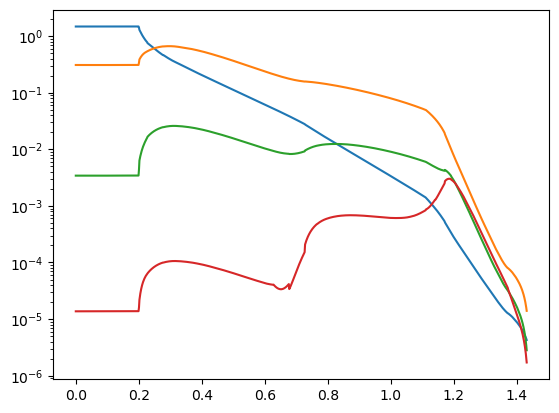

In [108]:
from finite_elements.test_breeding_blanket import _interp_x
d_other_dim = 5.0
x= _interp_x()
y = jnp.full_like(x, 0.5 * d_other_dim)
xy = jnp.stack([x,y], axis=-1)
phis = [solution_domain.interpolate(xy, values_lower_triangular[i, 0]) for i in range(MGOP.n_energy_groups)]
#phi1 = solution_domain.interpolate(xy, total_solution[1,0])

plt.semilogy(x, onp.array(phis).T)
#plt.semilogy(x, phi1)

In [114]:
from finite_elements.test_breeding_blanket import _bb_sb
import StellBlanket as SB


nte, source = _bb_sb(2,2, base_region_sizes(), base_resolutions(), 5.0, 3, 3)
print(nte)
print(source)
solution_options = SB.Generic_Elements.Solution_Options(tolerance=1e-20, maximum_iterations=200)


SB.Generic_Elements.Run_Forward(nte, source, solution_options)
    


x = onp.array(_interp_x())
y = onp.zeros_like(x)
z = onp.zeros_like(x)

xyz = onp.stack([x, y, z], axis = -1)
phisb = [SB.Generic_Elements.Interpolate_Moments(xyz, nte.global_moment_solution, nte.energy_set[i], 0, 0) * onp.sqrt(4 * onp.pi) for i in range(MGOP.n_energy_groups)]

MatrixFreeNTEReal(
	Memory usage:
		Global_Solution:
			Maximum:   0.000482798 GiB
		Precomputed_Scattering_Source:
			Precomp:   0.000482798 GiB
			Values:    0 MiB
		Global_Moment_Solution:
			Maximum:   0.000965595 GiB
			Per group: 0.000241399 GiB
		GMRES Option:
			0.00168979 GiB plus GMRES_restart * 0.000241399 GiB
			GMRES_restart = 10: 0.00410378 GiB
			Approx GMRES total GMRES_restart = 10: 0.00651777 GiB
		BiCGSTAB option:
			Base:      0.00193119 GiB
			Total:     0.00434518GiB 
		)

Combined_Layer_Source([Constant_Source(value=1, Energy_Group=0), Zero Source, Zero Source, Zero Source, Zero Source, Zero Source, Zero Source, Zero Source])
BiCGSTAB completed after 31 iterations with final error: 3.6599e-21
BiCGSTAB completed after 85 iterations with final error: 6.79413e-21
BiCGSTAB completed after 83 iterations with final error: 8.45438e-21
BiCGSTAB completed after 57 iterations with final error: 5.19589e-21


In [117]:
help(nte.energy_set)

Help on Energy_Set in module StellBlanket.generic_elements_cpp object:

class Energy_Set(builtins.object)
 |  Energy_Set(*args, **kwargs)
 |
 |  Methods defined here:
 |
 |  Boundaries(...)
 |      Boundaries(self) -> numpy.ndarray[dtype=float64, shape=(*), order='C']
 |
 |  Return_Dictionary(...)
 |      Return_Dictionary(self) -> object
 |
 |  Save_HDF5(...)
 |      Save_HDF5(self, Filename: str) -> None
 |
 |  __getitem__(...)
 |      __getitem__(self, arg: int, /) -> StellBlanket.generic_elements_cpp.Energy_Group
 |
 |  __init__(...)
 |      __init__(self, Energy_Bounds: numpy.ndarray[dtype=float64, shape=(*), order='C']) -> None
 |      __init__(self, Energy_Bounds: collections.abc.Sequence[float]) -> None
 |      __init__(self, Lower_Bounds: numpy.ndarray[dtype=float64, shape=(*), order='C'], Upper_Bounds: numpy.ndarray[dtype=float64, shape=(*), order='C']) -> None
 |      __init__(self, Lower_Bounds: collections.abc.Sequence[float], Upper_Bounds: collections.abc.Sequence[float])

In [111]:
onp.testing.assert_allclose(onp.array(phis), phisb, rtol=1e-10, atol=1e-10)

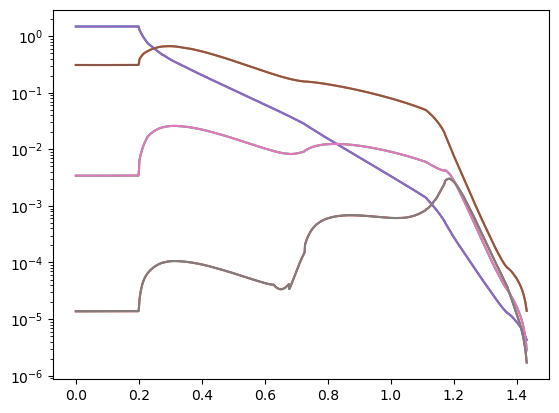

In [70]:
plt.semilogy(x,onp.array(phisb).T)
plt.semilogy(x,onp.array(phis).T)
